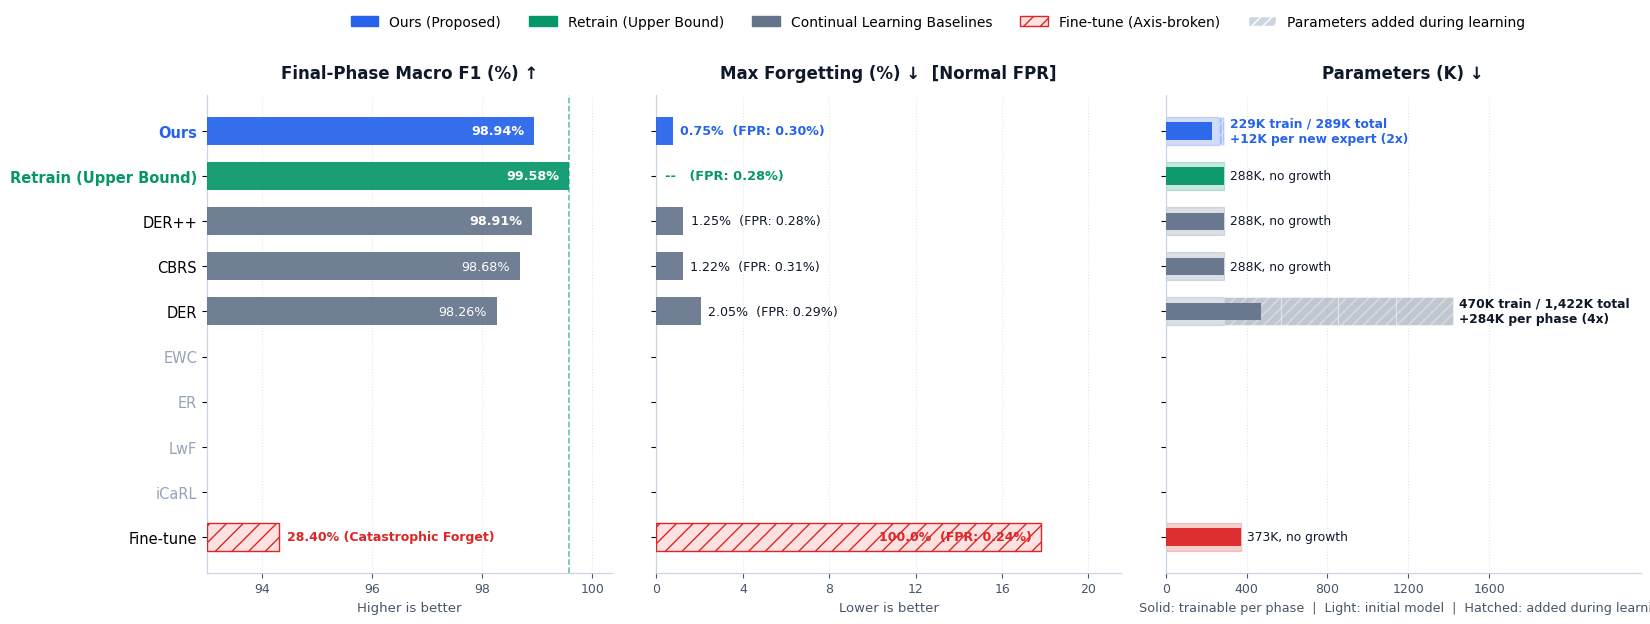

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ==============================================================================
# 1. DATA (None = row left empty this week)
# ==============================================================================
methods = ["Ours", "Retrain (Upper Bound)", "DER++", "CBRS", "DER",
           "EWC", "ER", "LwF", "iCaRL", "Fine-tune"]

# Unit: %  ("NA" for Retrain forgetting -> "--"; None -> empty row)
macro_f1   = [98.94, 99.58, 98.91, 98.68, 98.26, None, None, None, None, 28.40]
forget_max = [ 0.75,  "NA",  1.25,  1.22,  2.05, None, None, None, None, 100.00]
normal_fpr = [ 0.30,  0.28,  0.28,  0.31,  0.29, None, None, None, None,  0.24]

# Unit: thousand parameters (K)
train_params_k = [228.711, 287.509, 287.509, 287.509,  470.496, None, None, None, None, 372.825]
# Model size at phase 1, size added by each growth step, number of growth steps.
# Ours: one expert + one router row per expansion (12,032 + 58 = 12,090), 2 expansions.
# DER: one full encoder per phase after phase 1, 4 additions.
base_params_k  = [264.947, 287.509, 287.509, 287.509,  287.509, None, None, None, None, 372.825]
step_params_k  = [ 12.090,    None,    None,    None,  283.671, None, None, None, None,    None]
n_steps        = [      2,       0,       0,       0,        4, None, None, None, None,       0]

# --- NEXT WEEK (uncomment to show all 10 methods) ---
# macro_f1       = [98.94, 99.58, 98.91, 98.68, 98.26, 98.11, 97.99, 97.72, 94.90, 28.40]
# forget_max     = [ 0.75,  "NA",  1.25,  1.22,  2.05,  2.10,  2.48,  2.10, 13.34, 100.00]
# normal_fpr     = [ 0.30,  0.28,  0.28,  0.31,  0.29,  0.37,  0.34,  0.46,  0.57,  0.24]
# train_params_k = [228.711, 287.509, 287.509, 287.509,  470.496, 287.509, 287.509, 287.509, 287.509, 372.825]
# base_params_k  = [264.947, 287.509, 287.509, 287.509,  287.509, 287.509, 287.509, 287.509, 287.509, 372.825]
# step_params_k  = [ 12.090,    None,    None,    None,  283.671,    None,    None,    None,    None,    None]
# n_steps        = [      2,       0,       0,       0,        4,       0,       0,       0,       0,       0]

# Reverse so that the first method is drawn on top
idx = np.arange(len(methods))[::-1]
rev = lambda a: [a[i] for i in idx]
methods, macro_f1, forget_max, normal_fpr = rev(methods), rev(macro_f1), rev(forget_max), rev(normal_fpr)
train_params_k, base_params_k, step_params_k, n_steps = (rev(train_params_k), rev(base_params_k),
                                                         rev(step_params_k), rev(n_steps))

def get_color(name):
    if "Ours" in name:      return "#2563EB"
    if "Retrain" in name:   return "#059669"
    if "Fine-tune" in name: return "#DC2626"
    return "#64748B"

colors = [get_color(m) for m in methods]

# ==============================================================================
# 2. THREE-PANEL FIGURE (16:9)
# ==============================================================================
plt.rcParams.update({"font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
                     "axes.edgecolor": "#CBD5E1", "axes.linewidth": 0.9})

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18.5, 6.2), sharey=True,
                                    gridspec_kw={"width_ratios": [1.15, 1.32, 1.35], "wspace": 0.10})
fig.patch.set_facecolor("white")
y = np.arange(len(methods))
bar_h = 0.62

# --- PANEL 1: FINAL-PHASE MACRO F1 (%) ---
f1_min, f1_max = 93.0, 100.35
ax1.set_xlim(f1_min, f1_max)
ax1.set_xticks([94, 96, 98, 100])
ax1.axvline(99.58, color="#059669", linestyle="--", linewidth=1.1, alpha=0.65, zorder=1)
for i, (m, val, col) in enumerate(zip(methods, macro_f1, colors)):
    if val is None:
        continue
    if val < f1_min:
        ax1.barh(i, 1.3, left=f1_min, height=bar_h, color="#FEE2E2", edgecolor="#DC2626",
                 hatch="//", linewidth=1.0, zorder=3)
        ax1.text(f1_min + 1.45, i, f"{val:.2f}% (Catastrophic Forget)", va="center", ha="left",
                 fontsize=9, fontweight="bold", color="#DC2626")
    else:
        ax1.barh(i, val - f1_min, left=f1_min, height=bar_h, color=col, alpha=0.92, zorder=3)
        bold = any(k in m for k in ["Ours", "DER++", "Retrain"])
        if val > 96.5:
            ax1.text(val - 0.18, i, f"{val:.2f}%", va="center", ha="right", fontsize=9.2,
                     fontweight="bold" if bold else "normal", color="white")
        else:
            ax1.text(val + 0.15, i, f"{val:.2f}%", va="center", ha="left", fontsize=9.2, color="#0F172A")
ax1.set_title("Final-Phase Macro F1 (%) ↑", fontsize=12, fontweight="bold", pad=12, color="#0F172A")
ax1.set_xlabel("Higher is better", fontsize=9.5, color="#475569")

# --- PANEL 2: MAX FORGETTING (%) & NORMAL FPR (%) ---
ax2.set_xlim(0, 21.5)
ax2.set_xticks([0, 4, 8, 12, 16, 20])
for i, (m, fg, fpr, col) in enumerate(zip(methods, forget_max, normal_fpr, colors)):
    if fg is None:
        continue
    if fg == "NA":
        ax2.text(0.4, i, f"--   (FPR: {fpr:.2f}%)", va="center", ha="left", fontsize=9.3,
                 fontweight="bold", color="#059669")
    elif fg > 18.0:
        ax2.barh(i, 17.8, height=bar_h, color="#FEE2E2", edgecolor="#DC2626", hatch="//",
                 linewidth=1.0, zorder=3)
        ax2.text(17.4, i, f"100.0%  (FPR: {fpr:.2f}%)", va="center", ha="right", fontsize=9,
                 fontweight="bold", color="#DC2626")
    else:
        ax2.barh(i, fg, height=bar_h, color=col, alpha=0.92, zorder=3)
        ax2.text(fg + 0.35, i, f"{fg:.2f}%  (FPR: {fpr:.2f}%)", va="center", ha="left", fontsize=9.1,
                 fontweight="bold" if "Ours" in m else "normal",
                 color="#2563EB" if "Ours" in m else "#0F172A")
ax2.set_title("Max Forgetting (%) ↓  [Normal FPR]", fontsize=12, fontweight="bold", pad=12, color="#0F172A")
ax2.set_xlabel("Lower is better", fontsize=9.5, color="#475569")

# --- PANEL 3: PARAMETERS (base model + growth during continual learning) ---
ax3.set_xlim(0, 2350)
ax3.set_xticks([0, 400, 800, 1200, 1600])
for i, (m, base, step, ns, trn, col) in enumerate(zip(methods, base_params_k, step_params_k,
                                                       n_steps, train_params_k, colors)):
    if base is None:
        continue
    # base model (light) and every growth step (hatched, one segment per step)
    ax3.barh(i, base, height=bar_h, color=col, alpha=0.22, edgecolor=col, linewidth=0.9, zorder=2)
    total = base
    for _ in range(ns or 0):
        ax3.barh(i, step, left=total, height=bar_h, color=col, alpha=0.40, edgecolor="white",
                 hatch="///", linewidth=0.8, zorder=2)
        total += step
    # trainable parameters per phase (solid, thinner)
    ax3.barh(i, trn, height=bar_h * 0.62, color=col, alpha=0.95, zorder=3)

    if ns:
        grow = f"+{step:,.0f}K per {'new expert' if 'Ours' in m else 'phase'})"
        label = f"{trn:,.0f}K train / {total:,.0f}K total\n{grow}"
    else:
        label = f"{base:,.0f}K, no growth"
    ax3.text(total + 30, i, label, va="center", ha="left", fontsize=8.8, linespacing=1.25,
             fontweight="bold" if m in ("Ours", "DER") else "normal",
             color="#2563EB" if "Ours" in m else "#0F172A")
ax3.set_title("Parameters (K) ↓", fontsize=12, fontweight="bold", pad=12, color="#0F172A")
ax3.set_xlabel("Solid: trainable per phase  |  Light: initial model  |  Hatched: added during learning",
               fontsize=9.2, color="#475569")

# --- COMMON STYLE ---
ax1.set_yticks(y)
ax1.set_yticklabels(methods, fontsize=10.5)
for tick_label, val in zip(ax1.get_yticklabels(), macro_f1):
    t = tick_label.get_text()
    if "Ours" in t:
        tick_label.set_fontweight("bold"); tick_label.set_color("#2563EB")
    elif "Retrain" in t:
        tick_label.set_fontweight("bold"); tick_label.set_color("#059669")
    elif val is None:
        tick_label.set_color("#94A3B8")
for ax in (ax1, ax2, ax3):
    ax.grid(axis="x", linestyle=":", alpha=0.5, color="#CBD5E1", zorder=0)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", labelsize=9, colors="#475569")

legend_handles = [
    mpatches.Patch(color="#2563EB", label="Ours (Proposed)"),
    mpatches.Patch(color="#059669", label="Retrain (Upper Bound)"),
    mpatches.Patch(color="#64748B", label="Continual Learning Baselines"),
    mpatches.Patch(facecolor="#FEE2E2", edgecolor="#DC2626", hatch="//", label="Fine-tune (Axis-broken)"),
    mpatches.Patch(facecolor="#CBD5E1", edgecolor="white", hatch="///", label="Parameters added during learning"),
]
fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.52, 1.03),
           ncol=5, frameon=False, fontsize=10)

plt.savefig("comparison_slide.png", dpi=300, bbox_inches="tight")
plt.show()